In [1]:
# Setup cell
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import os
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

In [2]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Data Reading and  Pre-processing

In [3]:
# Read Weather dataset
df = pd.read_csv('/content/drive/MyDrive/mpi_roof_2025.csv', encoding = "unicode_escape")

# Print first five rows of datatset
df.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m²),PAR (µmol/m²/s),max. PAR (µmol/m²/s),Tlog (degC),CO2 (ppm)
0,01.01.2025 00:10:00,997.30,-1.56,271.80,-2.97,90.0,5.45,4.90,0.54,3.06,...,1.61,3.87,148.9,0.0,0.0,0.0,0.0,0.0,6.24,456.9
1,01.01.2025 00:20:00,997.05,-0.90,272.48,-2.66,87.8,5.72,5.02,0.70,3.14,...,1.71,3.05,145.6,0.0,0.0,0.0,0.0,0.0,6.32,451.7
2,01.01.2025 00:30:00,996.96,-0.51,272.88,-2.44,86.7,5.89,5.10,0.78,3.19,...,1.61,3.31,146.9,0.0,0.0,0.0,0.0,0.0,6.46,451.0
3,01.01.2025 00:40:00,996.77,-0.27,273.14,-2.26,86.3,5.99,5.17,0.82,3.23,...,1.86,2.93,137.0,0.0,0.0,0.0,0.0,0.0,6.63,450.4
4,01.01.2025 00:50:00,996.62,-0.09,273.33,-2.14,86.0,6.07,5.22,0.85,3.26,...,1.25,2.23,131.3,0.0,0.0,0.0,0.0,0.0,6.82,450.4


In [4]:
# Selecting only 'Date Time' and 'T(degC)'
df = df[['Date Time', 'T (degC)']]

# Dropping potential NA values
df = df.dropna()

# Converting to proper date time format
df["Date Time"] = pd.to_datetime(df["Date Time"], format = "mixed")
df = df.set_index("Date Time").asfreq("10min")

df.head()

,T (degC)
Date Time,
2025-01-01 00:10:00,-1.56
2025-01-01 00:20:00,-0.90
2025-01-01 00:30:00,-0.51
2025-01-01 00:40:00,-0.27
2025-01-01 00:50:00,-0.09


In [5]:
# Select rows for short-term forecasting
# Total of 72 hours
df_short = df["2025-01-01":"2025-01-05"]

# Select rows for long-term forecasting
# Total of 5 months
df_long = df["2025-01-01":"2025-05-31"]

print(f"Short-term shape: {df_short.shape}")
print(f"Long-term shape:  {df_long.shape}")

Short-term shape: (719, 1)
Long-term shape:  (21743, 1)


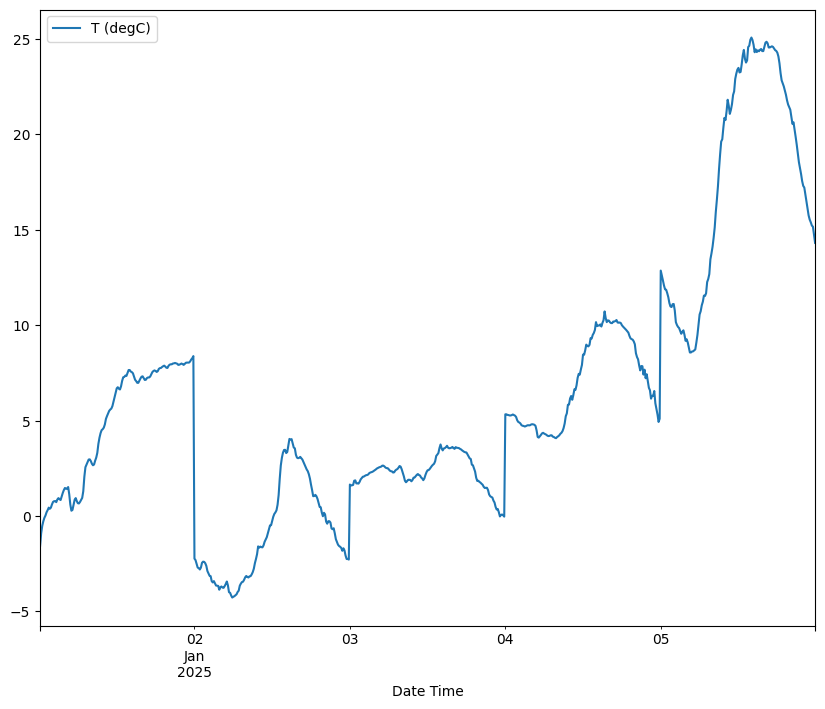

In [6]:
df_short.plot()
plt.show()

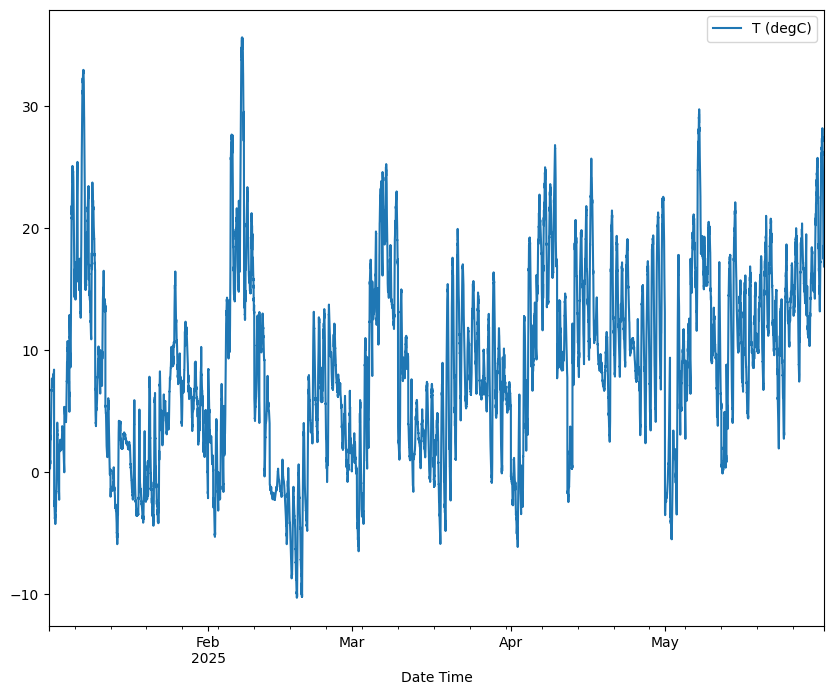

In [7]:
df_long.plot()
plt.show()

# 2. Short-Term Forecasting

In [8]:
# Split into training and testing data
# Training: 48 hours
# Testing: 24 hours
train = df_short["2025-01-01":"2025-01-04 23:50:00"]
test  = df_short["2025-01-05":"2025-01-05 23:50:00"]

print(f"Train: {train.index.min()} → {train.index.max()} | {len(train)} rows")
print(f"Test:  {test.index.min()} → {test.index.max()} | {len(test)} rows")

# Resampling into 1hr intervals
train_hourly = train.resample("1h").mean()
test_hourly  = test.resample("1h").mean()

Train: 2025-01-01 00:10:00 → 2025-01-04 23:50:00 | 575 rows
Test:  2025-01-05 00:00:00 → 2025-01-05 23:50:00 | 144 rows


In [11]:
# Finding optimal parameters
from pmdarima import auto_arima

auto_model = auto_arima(
    train_hourly["T (degC)"],
    seasonal=True,
    m=24,                   # 24 hours = 1 day cycle
    stepwise=True,          # faster search
    trace=True,             # prints each model it tries
    suppress_warnings=True,
    information_criterion="aic",
    max_p=3, max_q=3,
    max_P=2, max_Q=2,
    d=1, D=1
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[24]             : AIC=inf, Time=3.85 sec
 ARIMA(0,1,0)(0,1,0)[24]             : AIC=290.781, Time=0.07 sec
 ARIMA(1,1,0)(1,1,0)[24]             : AIC=294.226, Time=0.35 sec
 ARIMA(0,1,1)(0,1,1)[24]             : AIC=294.271, Time=0.47 sec
 ARIMA(0,1,0)(1,1,0)[24]             : AIC=292.439, Time=0.30 sec
 ARIMA(0,1,0)(0,1,1)[24]             : AIC=292.457, Time=0.33 sec
 ARIMA(0,1,0)(1,1,1)[24]             : AIC=inf, Time=3.21 sec
 ARIMA(1,1,0)(0,1,0)[24]             : AIC=292.648, Time=0.11 sec
 ARIMA(0,1,1)(0,1,0)[24]             : AIC=292.660, Time=0.36 sec
 ARIMA(1,1,1)(0,1,0)[24]             : AIC=294.555, Time=1.15 sec
 ARIMA(0,1,0)(0,1,0)[24] intercept   : AIC=292.555, Time=0.12 sec

Best model:  ARIMA(0,1,0)(0,1,0)[24]          
Total fit time: 10.352 seconds
                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:

In [12]:
# Fit SARIMAX Model
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(train_hourly["T (degC)"],
                order=auto_model.order,
                seasonal_order=auto_model.seasonal_order)

fit = model.fit(disp=False)
forecast = fit.forecast(steps=24)


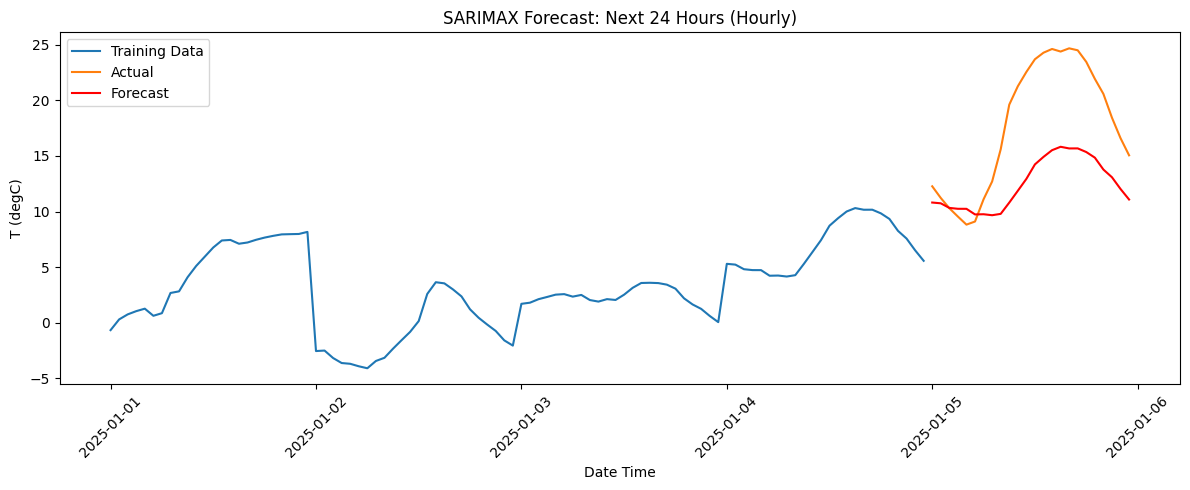

In [13]:
# Forecast plot
plt.figure(figsize=(12, 5))
plt.plot(train_hourly.index, train_hourly["T (degC)"], label="Training Data")
plt.plot(test_hourly.index,  test_hourly["T (degC)"],  label="Actual")
plt.plot(test_hourly.index,  forecast,                 label="Forecast", color="red")
plt.title("SARIMAX Forecast: Next 24 Hours (Hourly)")
plt.xlabel("Date Time")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Evaluating through RMSE
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae  = mean_absolute_error(test_hourly["T (degC)"], forecast)
rmse = np.sqrt(mean_squared_error(test_hourly["T (degC)"], forecast))
print(f"Optimal order:          {auto_model.order}")
print(f"Optimal seasonal order: {auto_model.seasonal_order}")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

Optimal order:          (0, 1, 0)
Optimal seasonal order: (0, 1, 0, 24)
MAE:  5.541
RMSE: 6.548


In [16]:
# Saving results to CSV
sarima_results = pd.DataFrame({
    "actual":   test_hourly["T (degC)"].values,
    "forecast": forecast.values
}, index=test_hourly.index)

sarima_results.to_csv("/content/drive/MyDrive/sarima_results.csv")

# 3. Long-term Forecasting

In [17]:
# Trian/test split
# Training: 4 months
# Testing: 1 month
train_long = df_long["2025-01-01":"2025-04-30"]
test_long  = df_long["2025-05-01":"2025-05-31"]

# Resample into daily intervals
train_long_daily = train_long.resample("1D").mean()
test_long_daily  = test_long.resample("1D").mean()

print(f"Train: {train_long_daily.index.min()} → {train_long_daily.index.max()} | {len(train_long_daily)} rows")
print(f"Test:  {test_long_daily.index.min()} → {test_long_daily.index.max()} | {len(test_long_daily)} rows")

Train: 2025-01-01 00:00:00 → 2025-04-30 00:00:00 | 120 rows
Test:  2025-05-01 00:00:00 → 2025-05-31 00:00:00 | 31 rows


In [18]:
# Hyperparameter search
auto_model_long = auto_arima(
    train_long_daily["T (degC)"],
    seasonal=True,
    m=7,                    # weekly cycle on daily data
    stepwise=True,
    trace=True,
    suppress_warnings=True,
    information_criterion="aic",
    max_p=3, max_q=3,
    max_P=2, max_Q=2,
    d=1, D=1
)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[7]             : AIC=674.499, Time=0.43 sec
 ARIMA(0,1,0)(0,1,0)[7]             : AIC=740.421, Time=0.03 sec
 ARIMA(1,1,0)(1,1,0)[7]             : AIC=704.268, Time=0.11 sec
 ARIMA(0,1,1)(0,1,1)[7]             : AIC=inf, Time=0.32 sec
 ARIMA(2,1,2)(0,1,1)[7]             : AIC=672.570, Time=0.97 sec
 ARIMA(2,1,2)(0,1,0)[7]             : AIC=713.364, Time=1.11 sec
 ARIMA(2,1,2)(0,1,2)[7]             : AIC=674.512, Time=2.87 sec
 ARIMA(2,1,2)(1,1,0)[7]             : AIC=689.851, Time=0.21 sec
 ARIMA(2,1,2)(1,1,2)[7]             : AIC=inf, Time=1.48 sec
 ARIMA(1,1,2)(0,1,1)[7]             : AIC=671.006, Time=0.28 sec
 ARIMA(1,1,2)(0,1,0)[7]             : AIC=712.054, Time=0.09 sec
 ARIMA(1,1,2)(1,1,1)[7]             : AIC=672.991, Time=0.40 sec
 ARIMA(1,1,2)(0,1,2)[7]             : AIC=672.994, Time=0.69 sec
 ARIMA(1,1,2)(1,1,0)[7]             : AIC=688.056, Time=0.14 sec
 ARIMA(1,1,2)(1,1,2)[7]             : AIC=inf, Time=1.3

In [ ]:
# m=7 for weekly seasonality on daily data
model_long = SARIMAX(train_long_daily["T (degC)"],
                     order=auto_model_long.order,
                     seasonal_order=auto_model_long.seasonal_order)

fit_long = model_long.fit(disp=False)
forecast_long = fit_long.forecast(steps=len(test_long_daily))

                                      SARIMAX Results                                      
Dep. Variable:                            T (degC)   No. Observations:                  120
Model:             SARIMAX(2, 1, 2)x(1, 1, [1], 7)   Log Likelihood                -330.250
Date:                             Wed, 03 Jun 2026   AIC                            674.499
Time:                                     23:21:26   BIC                            693.529
Sample:                                 01-01-2025   HQIC                           682.220
                                      - 04-30-2025                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4259      0.258     -1.650      0.099      -0.932       0.080
ar.L2          0.1770      

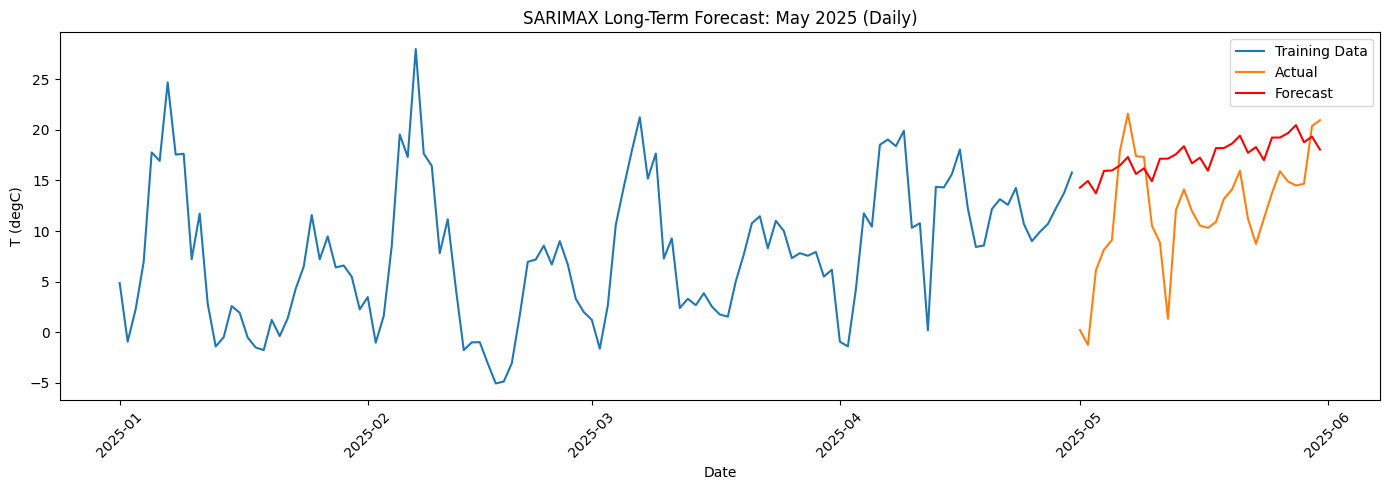

In [19]:
# Forecast next 31 days (May)
forecast_long = fit_long.forecast(steps=len(test_long_daily))

# Plot forecast results
plt.figure(figsize=(14, 5))
plt.plot(train_long_daily.index, train_long_daily["T (degC)"], label="Training Data")
plt.plot(test_long_daily.index,  test_long_daily["T (degC)"],  label="Actual")
plt.plot(test_long_daily.index,  forecast_long,                label="Forecast", color="red")
plt.title("SARIMAX Long-Term Forecast: May 2025 (Daily)")
plt.xlabel("Date")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
# Evaluating results
rmse = np.sqrt(mean_squared_error(test_long_daily["T (degC)"], forecast_long))
print(f"RMSE: {rmse:.3f}")

RMSE: 7.052


In [21]:
# Saving results to csv
sarima_long_results = pd.DataFrame({
    "actual":   test_long_daily["T (degC)"].values,
    "forecast": forecast_long.values
}, index=test_long_daily.index)

sarima_long_results.to_csv("/content/drive/MyDrive/sarima_long_results.csv")